# Etapa 3: Descomposición Espectral Matching Pursuit (MPD)

Este notebook implementa el **Paso 3**: la descomposición voraz (*greedy*) de la traza sísmica en átomos elementales de Morlet y el cálculo de la **Distribución Tiempo-Frecuencia (TFD)**.

### Algoritmo MPD
1. Se calcula la energía inicial de la señal residual: $E_0 = \|R_0\|^2$.
2. En cada iteración $n$, mediante la señal analítica de Hilbert se estiman los atributos instantáneos:
   * Tiempo central de llegada $t_0 = \arg\max |z(t)|$.
   * Amplitud envolvente $A_n = |z(t_0)|$.
   * Fase instantánea $\phi_n = \arg(z(t_0))$.
   * Frecuencia instantánea $f_n = \frac{1}{2\pi} \frac{d\theta}{dt}(t_0)$.
3. Se selecciona y sustrae el átomo de Morlet óptimo: $R_n(t) = R_{n-1}(t) - A_n m_n(t)$.
4. Se acumula en la traza modelada $\hat{s}(t) = \sum A_n m_n(t)$ hasta alcanzar el umbral de energía (`cutoff`).

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

MODULE_DIR = os.path.abspath('../3_Python_Code')
if MODULE_DIR not in sys.path:
    sys.path.insert(0, MODULE_DIR)

from config import MPDConfig, MorletDictionaryConfig
from matching_pursuit import decompose_trace_mpd, compute_time_frequency_distribution
from io_seismic import load_mat_seismic

# Cargamos los datos preprocesados de la Etapa 1
mat_data, _ = load_mat_seismic('data_processed/traza_preprocesada.mat')
trace = mat_data.squeeze()
sample_rate_s = 0.002
t_vec = np.arange(len(trace)) * sample_rate_s
print(f'Traza cargada con {len(trace)} muestras.')

Traza cargada con 1001 muestras.


## 1. Ejecución de la Descomposición Matching Pursuit

In [2]:
mpd_cfg = MPDConfig(energy_cutoff=0.003, max_iterations=150)
dict_cfg = MorletDictionaryConfig(f_min=5.0, f_max=100.0, df=1.0, wavelet_half_duration_s=0.25)

mpd_results = decompose_trace_mpd(
    trace,
    sample_rate_s=sample_rate_s,
    mpd_config=mpd_cfg,
    dict_config=dict_cfg
)

n_atoms = len(mpd_results['atoms'])
final_energy = mpd_results['energy_history'][-1] * 100
print(f'Iteraciones completadas: {mpd_results["iterations"]}')
print(f'Átomos de Morlet extraídos: {n_atoms}')
print(f'Energía residual final: {final_energy:.3f}% (explicó {100-final_energy:.3f}% de la señal).')

Iteraciones completadas: 150
Átomos de Morlet extraídos: 150
Energía residual final: 2.563% (explicó 97.437% de la señal).


## 2. Reconstrucción y Señal Residual

Comparamos la traza original frente a la reconstruida por la suma de átomos y evaluamos el decaimiento de energía.

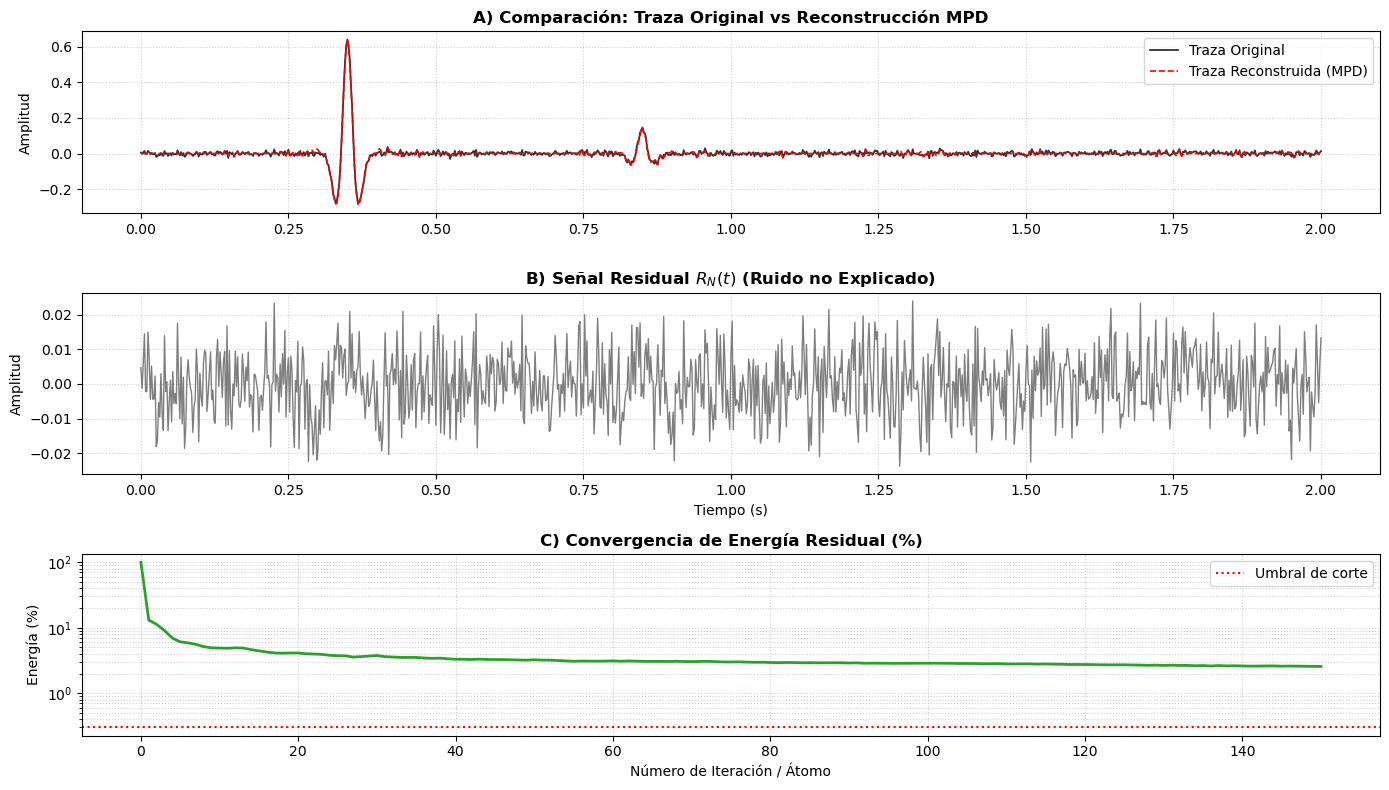

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=False)

# A: Traza original vs modelada
axes[0].plot(t_vec, trace, 'k-', label='Traza Original', linewidth=1.3, alpha=0.8)
axes[0].plot(t_vec, mpd_results['modeled_trace'], 'r--', label='Traza Reconstruida (MPD)', linewidth=1.2)
axes[0].set_title('A) Comparación: Traza Original vs Reconstrucción MPD', fontweight='bold')
axes[0].set_ylabel('Amplitud')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.6)

# B: Traza residual
axes[1].plot(t_vec, mpd_results['residual_trace'], color='#7f7f7f', linewidth=1.0)
axes[1].set_title('B) Señal Residual $R_N(t)$ (Ruido no Explicado)', fontweight='bold')
axes[1].set_ylabel('Amplitud')
axes[1].set_xlabel('Tiempo (s)')
axes[1].grid(True, linestyle=':', alpha=0.6)

# C: Convergencia de energía
iters = np.arange(len(mpd_results['energy_history']))
axes[2].plot(iters, np.array(mpd_results['energy_history']) * 100, color='#2ca02c', linewidth=2.0)
axes[2].axhline(mpd_cfg.energy_cutoff * 100, color='red', linestyle=':', label='Umbral de corte')
axes[2].set_title('C) Convergencia de Energía Residual (%)', fontweight='bold')
axes[2].set_xlabel('Número de Iteración / Átomo')
axes[2].set_ylabel('Energía (%)')
axes[2].set_yscale('log')
axes[2].legend()
axes[2].grid(True, linestyle=':', which='both', alpha=0.6)

plt.tight_layout()
plt.show()

## 3. Construcción del Espectrograma Tiempo-Frecuencia (TFD)

Sintetizamos el mapa continuo de densidad de energía tiempo-frecuencia proyectando los átomos de Morlet.

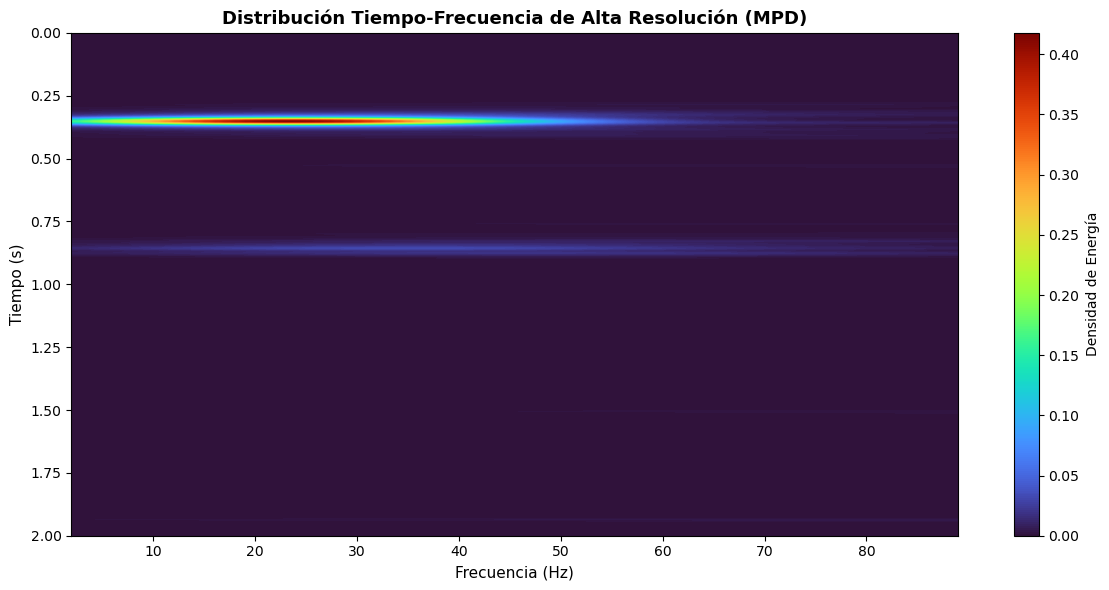

Distribución TF exportada a data_processed/tfdist_results.npz


In [4]:
f_eval = np.arange(2.0, 90.0, 1.0)
tfdist = compute_time_frequency_distribution(
    mpd_results['atoms'],
    time_vector=t_vec,
    freq_vector=f_eval,
    k_param=0.2
)

plt.figure(figsize=(12, 6))
im = plt.imshow(
    tfdist,
    extent=[f_eval[0], f_eval[-1], t_vec[-1], t_vec[0]],
    aspect='auto',
    cmap='turbo'
)
plt.title('Distribución Tiempo-Frecuencia de Alta Resolución (MPD)', fontsize=13, fontweight='bold')
plt.xlabel('Frecuencia (Hz)', fontsize=11)
plt.ylabel('Tiempo (s)', fontsize=11)
plt.colorbar(im, label='Densidad de Energía')
plt.tight_layout()
plt.show()

# Guardar distribución tiempo-frecuencia para etapas 4 y 5
np.savez('data_processed/tfdist_results.npz', tfdist=tfdist, t_vec=t_vec, f_eval=f_eval)
print('Distribución TF exportada a data_processed/tfdist_results.npz')